In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn import metrics 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split

In [47]:
dataset = pd.read_csv("insurance.csv")

In [49]:
dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [51]:
dataset["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [53]:
dataset.shape

(1338, 7)

In [55]:
dataset.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

/var/folders/g7/b1yz35mn0vld78lzsmcmy3q80000gn/T/ipykernel_4621/3677671015.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["age"])
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='age', ylabel='Density'>

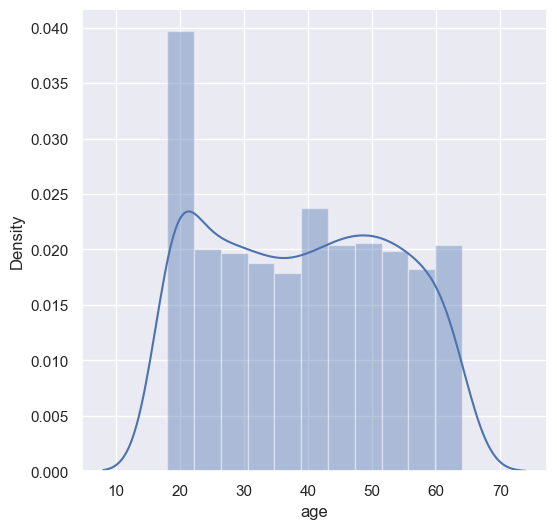

In [57]:
sns.set()
plt.figure(figsize=(6,6))
sns.distplot(data["age"])


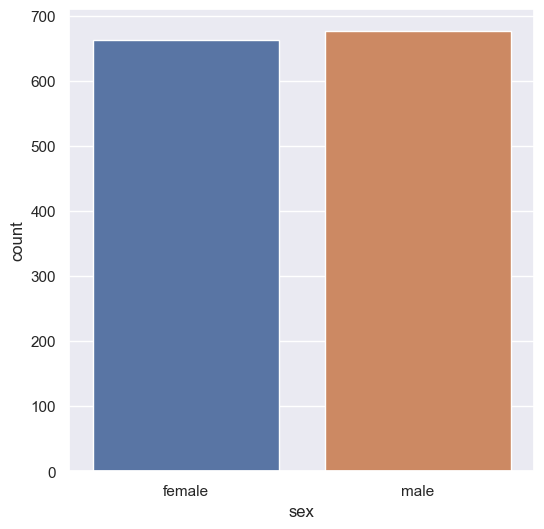

In [61]:
plt.figure(figsize=(6,6))
sns.countplot(x= "sex",data=dataset)
plt.show()

/var/folders/g7/b1yz35mn0vld78lzsmcmy3q80000gn/T/ipykernel_4621/1546902585.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["bmi"])
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='bmi', ylabel='Density'>

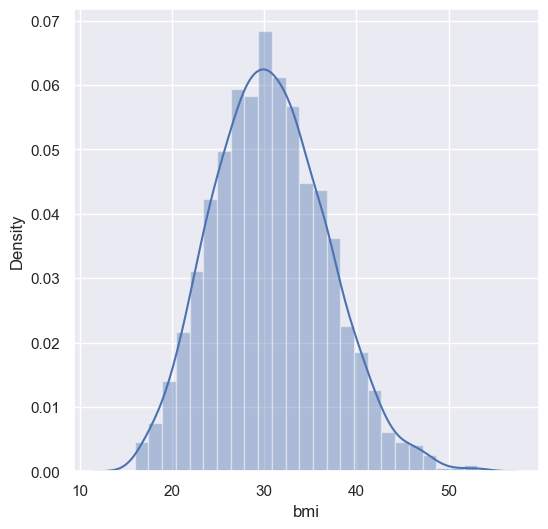

In [67]:
sns.set()
plt.figure(figsize=(6,6))
sns.distplot(data["bmi"])


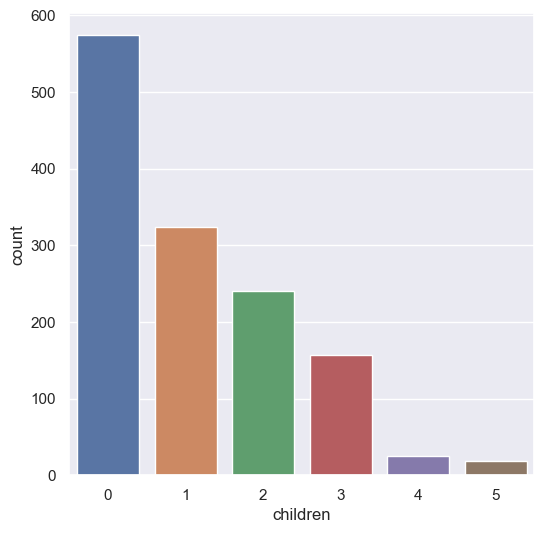

In [69]:
plt.figure(figsize=(6,6))
sns.countplot(x= "children",data=dataset)
plt.show()

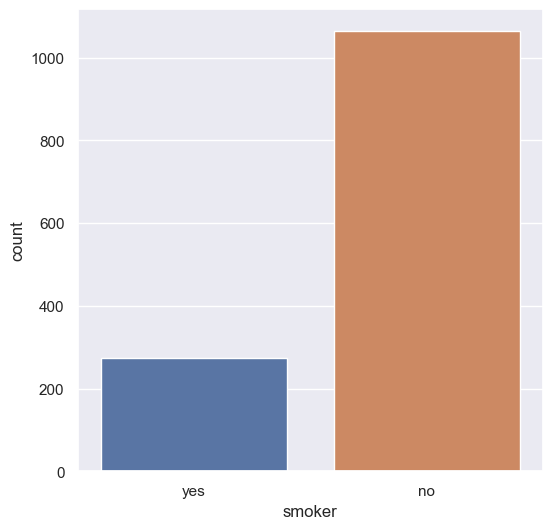

In [71]:
plt.figure(figsize=(6,6))
sns.countplot(x= "smoker",data=dataset)
plt.show()

In [65]:
dataset["sex"].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [8]:
pd.set_option('future.no_silent_downcasting', True)
data.replace({"sex":{"female":0,"male":1},"smoker":{"no":0,"yes":1},"region":{"southwest":0,"southeast":1,"northwest":2,"northeast":3}},inplace=True)

In [9]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,0,16884.92400
1,18,1,33.770,1,0,1,1725.55230
2,28,1,33.000,3,0,1,4449.46200
3,33,1,22.705,0,0,2,21984.47061
4,32,1,28.880,0,0,2,3866.85520


In [10]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,1,30.97,3,0,2,10600.5483
1334,18,0,31.92,0,0,3,2205.9808
1335,18,0,36.85,0,0,1,1629.8335
1336,21,0,25.80,0,0,0,2007.9450
1337,61,0,29.07,0,1,2,29141.3603


In [11]:
X= data.drop(columns="charges",axis=1)
Y= data["charges"]             

In [12]:
X_train,X_test,Y_train,Y_test= train_test_split(X,Y,test_size = 0.2 ,random_state=2)

In [13]:
model= LinearRegression()

In [14]:
model.fit(X_train,Y_train)

LinearRegression()

In [15]:
training_data_prediction= model.predict(X_train)

In [16]:
error = metrics.r2_score(Y_train,training_data_prediction)

In [17]:
error

0.7519923667088932

In [18]:
test_data_prediction= model.predict(X_test)

In [19]:
error2= metrics.r2_score(Y_test,test_data_prediction)

In [20]:
error2

0.7445422986536503

In [21]:
input_data = (58,0,31.825,2,0,3)
input_data_as_numpy_array= np.asarray(input_data)
data_reshaped = input_data_as_numpy_array.reshape(1,-1)
prediction = model.predict(data_reshaped)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [22]:
print(prediction)#13607 asıl deger

[14536.409527]
